# The Harvard Forest inverse problem

This notebook introduces the inverse problem that the algorithms in this repository solve:
calibrating the SIPNET land-surface model against measurements of carbon flux at Harvard Forest.
Each section states one part of the problem in mathematics, shows the object in the `lsmas`
package that holds it, and plots it.

Running the whole notebook takes about a minute; it runs SIPNET about 520 times. To open it, run
`uv sync` once and then `uv run jupyter lab` from the repository's root.

The notation is that of [`docs/notation.md`](../docs/notation.md), which every docstring in the
package also uses.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from probpipe import (
    NumericArrayBatch,
    log_prob,
    marginal,
    predictive_check,
    quantile,
    sample,
    workflow_run,
)
from pysipnet import ClimateDrivers

from lsmas import plots
from lsmas.data import load_harvard_forest
from lsmas.parameters import calibration_to_sipnet
from lsmas.priors import prior_medians
from lsmas.problems import load
from lsmas.problems.nee_likelihood import (
    NOISE_SCALE_PRIOR,
    OBSERVATIONS_PER_CLASS_YEAR,
    REFERENCE_VARIANCE,
)
from lsmas.sipnet import SIPNETSimulator

YEAR = 2015  # the year that the one-year figures show

## 1. The problem in one equation

SIPNET is a model of a forest's carbon and water. Given the weather and values of its parameters,
it predicts, among other things, the **net ecosystem exchange** (NEE): the net flow of CO₂ from
the forest to the atmosphere. A tower at Harvard Forest measures NEE. Calibration asks which
parameter values agree with those measurements, and how uncertain the values remain.

The answer is a probability distribution over the parameters, the **posterior**:

$$
\pi_\eta(\theta, s^2 \mid y) \;\propto\; \pi(\theta)\, \pi(s^2)
\prod_{i=1}^{n} \mathcal N\!\left(y_i \;\middle|\; G_i(\theta),\; s^2_{k(i)}\, v_i\right)^{\eta_i}.
$$

Each symbol is introduced in a later section:

| Symbol | Meaning | Section |
|---|---|---|
| $\theta \in \mathbb R^{d}$ | the $d = 46$ calibration parameters | 3 |
| $\pi(\theta)$ | their prior | 3 |
| $x(\theta) \in \mathbb R^{S}$ | SIPNET's NEE at each of its $S$ three-hour steps | 4 |
| $y \in \mathbb R^{n}$ | the $n = 400$ observed features | 5 |
| $A$ | the observation operator, which averages $x(\theta)$ as the features average the data | 5 |
| $G(\theta) = A\, x(\theta)$ | the forward map: the predicted features | 6 |
| $k(i)$ | the class of feature $i$, day or night | 5 |
| $v_i$, $s^2_k$ | the reference variance of feature $i$, and the noise scale of class $k$ | 7 |
| $\pi(s^2)$ | the prior of the noise scales | 7 |
| $\eta_i$ | the learning rate of feature $i$ | 7 |

In code, the whole problem is one object, loaded by name:

In [2]:
problem = load("harvard_forest", scales="inferred")
print(problem.describe())

harvard_forest: Harvard Forest NEE, 2012-2020, with all 46 calibration parameters (noise scales inferred).
Calibration parameters (46): photosynthetic_capacity, respiration_share, optimum_photosynthesis_temperature, photosynthesis_temperature_range, half_saturation_light, vapor_pressure_deficit_slope, vapor_pressure_deficit_exponent, light_extinction_coefficient, water_use_efficiency, water_removal_fraction, soil_water_holding_capacity, interception_evaporation_fraction, fast_flow_fraction, snow_melt_rate, aerodynamic_resistance_constant, soil_resistance_intercept, soil_resistance_slope, leaf_on_growing_degree_days, leaf_off_day, leaf_on_growth, leaf_off_fall_fraction, leaf_turnover_rate, leaf_allocation, wood_share_of_nonleaf_allocation, fine_root_share_of_root_allocation, wood_turnover_rate, fine_root_turnover_rate, coarse_root_turnover_rate, wood_respiration_rate_at_10c, wood_respiration_q10, fine_root_respiration_rate_at_10c, fine_root_respiration_q10, coarse_root_respiration_rate_

`problem` is an `InverseProblem`. Its attributes hold the parts of the equation:

| Attribute | Holds |
|---|---|
| `problem.prior` | $\pi(\theta)\, \pi(s^2)$, a ProbPipe distribution |
| `problem.likelihood` | $\mathcal N\!\left(y \mid G(\theta), s^2_{k(i)} v_i\right)$, a ProbPipe conditional distribution |
| `problem.forward` | $G$, a ProbPipe function |
| `problem.data` | $y$, as `{"nee": array}` |
| `problem.learning_rate` | $\eta$, as `{"nee": array}` |
| `problem.coordinates` | maps between $\theta$ and the coordinates the algorithms work in (section 10) |

`scales="inferred"` makes the two noise scales $s^2_{\mathrm{day}}$ and $s^2_{\mathrm{night}}$
parameters with a prior of their own. `scales="fixed"` sets both to 1 and changes nothing else.
This notebook uses the inferred scales throughout.

## 2. The site and its weather

The site is the Harvard Forest Environmental Measurement Site tower (AmeriFlux US-Ha1) in central
Massachusetts, at 42.54 °N, 72.17 °W, in a mostly deciduous forest. The data used here run from
2012 to 2020.

SIPNET is driven by the weather every three hours: air and soil temperature, photosynthetically
active radiation (PAR), vapor pressure deficit (VPD), precipitation and wind. The weather here is
the ERA5 reanalysis, corrected as `data/harvard_forest/PROVENANCE.md` describes.

`load_harvard_forest()` reads every input that ships with the repository into one
`HarvardForestData`:

| Field | Holds | Section |
|---|---|---|
| `driver_path` | the weather file SIPNET reads | 2 |
| `prior_table` | the prior of each calibration parameter, with its source | 3 |
| `fixed_sipnet_parameters` | the SIPNET parameters that are not calibrated | 3 |
| `step_ends` | the end time of each of SIPNET's three-hour steps | 4 |
| `features` | one row per observed feature, with its class, dates and value | 5 |
| `operator` | the observation operator $A$ | 5 |

In [3]:
data = load_harvard_forest()
data.driver_path

PosixPath('/Users/andrewroberts/Desktop/git-repos/lsm-active-subspace/data/harvard_forest/driver/era5_member_1.clim')

pySIPNET reads the weather file into an `xarray.Dataset`, one value per three-hour step. Each
variable's `attrs` give its units and its `kind`: a mean over the step, or a total over it.

In [4]:
driver = ClimateDrivers.from_path(data.driver_path, time_zone="UTC").xarray
driver

<xarray.Dataset> Size: 5MB
Dimensions:                              (time: 37992, bounds: 2)
Coordinates:
  * time                                 (time) datetime64[ns] 304kB 2012-01-...
    timestep_start                       (time) datetime64[ns] 304kB 2011-12-...
    timestep_length                      (time) timedelta64[ns] 304kB 03:00:0...
    year                                 (time) int64 304kB 2011 2012 ... 2024
    day_of_year                          (time) int64 304kB 365 1 1 ... 366 366
    hour_of_day                          (time) float64 304kB 21.0 0.0 ... 18.0
    time_bounds                          (time, bounds) datetime64[ns] 608kB ...
Dimensions without coordinates: bounds
Data variables:
    air_temperature                      (time) float64 304kB 1.768 ... 8.688
    soil_temperature                     (time) float64 304kB -0.914 ... 0.2142
    photosynthetically_active_radiation  (time) float64 304kB 0.01201 ... 4.831
    precipitation                        (time) float64 304kB 0.002269 ... 6....
    vapor_pressure_deficit               (time) float64 304kB 33.02 ... 525.3
    soil_vapor_pressure_deficit          (time) float64 304kB 0.0 0.0 ... 0.0
    vapor_pressure                       (time) float64 304kB 661.3 ... 603.2
    wind_speed                           (time) float64 304kB 2.891 ... 1.869
Attributes:
    Conventions:             CF-1.11
    source:                  SIPNET climate drivers, via pySIPNET
    time_convention:         The 'time' coordinate is the END of each timeste...
    time_zone:               UTC
    time_axis_source:        climate drivers
    timestep_length_source:  climate drivers

**Figure 1.** One year of the weather, as daily values. The helper `daily` sums a variable that is
a total over each step, such as precipitation, and averages the others. Look for the seasonal
cycle in temperature and light, which drives the seasonal cycle of NEE.

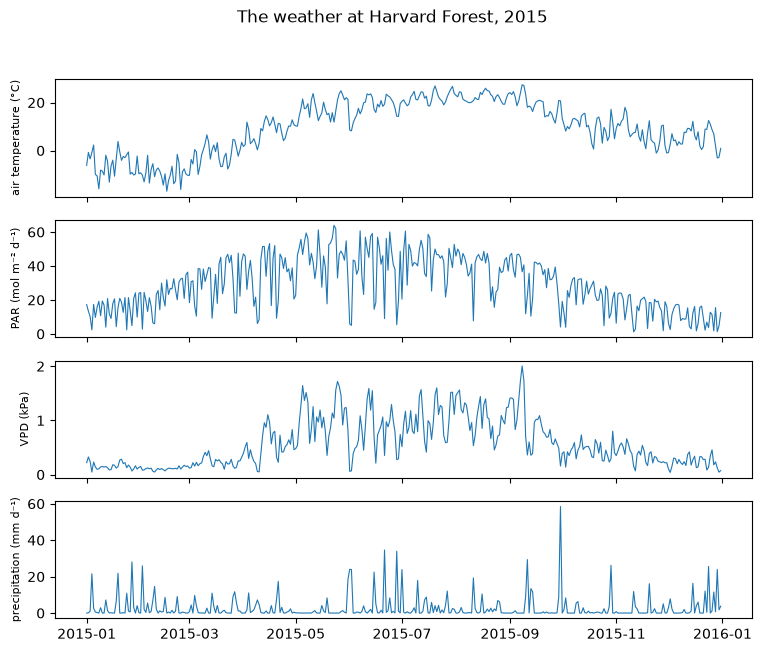

In [5]:
def daily(series):
    """Daily values of a three-hourly variable: totals summed, everything else averaged."""
    by_day = series.resample(time="1D")
    return by_day.sum() if series.attrs.get("kind") == "timestep_total" else by_day.mean()


one_year = driver.sel(time=str(YEAR))
panels = {
    "air temperature (°C)": daily(one_year["air_temperature"]),
    "PAR (mol m⁻² d⁻¹)": daily(one_year["photosynthetically_active_radiation"]),
    "VPD (kPa)": daily(one_year["vapor_pressure_deficit"]) / 1000,
    "precipitation (mm d⁻¹)": daily(one_year["precipitation"]),
}
figure, axes = plt.subplots(4, 1, figsize=(9, 7), sharex=True)
for axis, (label, series) in zip(axes, panels.items(), strict=True):
    axis.plot(series["time"], series, lw=0.8)
    axis.set_ylabel(label, fontsize=8)
figure.suptitle(f"The weather at Harvard Forest, {YEAR}");

## 3. The calibration parameters and their prior

### From SIPNET's parameters to the calibration parameters

pySIPNET sets 58 SIPNET parameters. Twelve of them are fixed and not calibrated:

- eight have no effect on NEE at this site under SIPNET's standard model options;
- three can be changed together with others without changing NEE at all, so only the
  combinations that matter are calibrated;
- one, the initial leaf area, is zero because each run starts on 1 January, when the forest has
  no leaves.

`data.fixed_sipnet_parameters` holds their values; `data/harvard_forest/sipnet_fixed.csv` gives
the reason for each.

In [6]:
pd.Series(data.fixed_sipnet_parameters, name="value")

daily_mean_photosynthesis_fraction      0.860623
leaf_carbon_fraction                    0.466075
leaf_carbon_per_area                   30.709200
leaf_area_index                         0.000000
leaf_on_day                           144.000000
leaf_on_soil_temperature               12.000000
growth_respiration_fraction             0.272493
litter_carbon                           0.000000
litter_breakdown_rate                   0.400000
litter_respired_fraction                0.500000
leaf_water_pool_depth                   0.200384
leaf_on_reallocation_fraction           0.200000
Name: value, dtype: float64

The other 46 quantities are the **calibration parameters** $\theta = (\theta_1, \dots,
\theta_{46})$. Most are SIPNET parameters under the same name. The rest are changes of variables
(in `lsmas.parameters`), each chosen so that the parameter's prior can be stated on its own:

- **Photosynthesis.** NEE depends on SIPNET's four photosynthesis parameters only through two
  combinations: the photosynthetic capacity $P$ and the share $\rho$ of it respired by leaves.
  $P$ and $\rho$ are calibrated.
- **Photosynthesis temperatures.** The optimum $T_{\mathrm{opt}}$ and the range $\Delta$, with
  $T_{\min} = T_{\mathrm{opt}} - \Delta$, so that $T_{\min} < T_{\mathrm{opt}}$ for any values.
- **Respiration.** Each rate is stated at 10 °C, $k_{10} = k\, Q_{10}$, rather than SIPNET's
  rate $k$ at 0 °C, since measurements report rates near the site's temperatures.
- **Allocation of growth.** Leaves take a share $\ell$, wood a share $w$ of the rest, and fine
  roots a share $f$ of what remains; coarse roots take the remainder. Any shares in $(0, 1)$ are
  valid.
- **Initial pools.** The initial wood, coarse-root and fine-root carbon are each an amount, in
  g C m⁻², rather than SIPNET's total and fractions.

`calibration_to_sipnet(theta, fixed)` maps calibration parameters and the fixed values to all 58
SIPNET parameters.

### The prior

The prior is a product of independent laws, one per parameter,

$$
\pi(\theta) = \prod_{j=1}^{46} \pi_j(\theta_j),
$$

each in one of four families:

- **log-normal**, $\log \theta_j \sim \mathcal N(\mu_j, \sigma_j^2)$, for a positive parameter;
- **logit-normal**, $\operatorname{logit} \theta_j \sim \mathcal N(\mu_j, \sigma_j^2)$, for a
  parameter in $(0, 1)$;
- **normal**, $\theta_j \sim \mathcal N(\mu_j, \sigma_j^2)$;
- **uniform** on an interval.

The log-normal and logit-normal priors are stated by their central 95% interval
$[\ell_j, u_j]$: for the log-normal,
$\mu_j = \tfrac12(\log \ell_j + \log u_j)$ and $\sigma_j = (\log u_j - \log \ell_j) / (2 \times
1.96)$, and likewise on the logit scale. `data.prior_table` is the specification, one row per
parameter, with the source of each interval:

In [7]:
data.prior_table

,units,family,lower,upper,mean,sd,source
parameter,,,,,,,
photosynthetic_capacity,nmol g-1 s-1,log_normal,140.00000,450.00000,NaN,NaN,P2
respiration_share,1,logit_normal,0.04000,0.20000,NaN,NaN,P2
optimum_photosynthesis_temperature,degC,normal,NaN,NaN,22.0,2.5,P2
photosynthesis_temperature_range,degC,log_normal,17.00000,31.00000,NaN,NaN,"BETY psnTMin 2.5-97.5% (-6.5, 6.6) below psnTO..."
half_saturation_light,mol m-2 d-1,log_normal,4.60000,26.30000,NaN,NaN,BETY
vapor_pressure_deficit_slope,kPa-1,log_normal,0.02000,0.12000,NaN,NaN,BETY median 0.050; R interval
vapor_pressure_deficit_exponent,1,log_normal,1.00000,3.00000,NaN,NaN,"Niwot range [1, 3]; BETY 1.5, Braswell 2"
light_extinction_coefficient,1,log_normal,0.38000,0.65000,NaN,NaN,BETY attenuation widened by BETY leafCSpWt spr...
water_use_efficiency,mg g-1 kPa,log_normal,7.90000,17.50000,NaN,NaN,BETY


`prior_medians` gives each parameter's prior median, exactly. SIPNET runs at these values in the
next section.

In [8]:
medians = prior_medians(data.prior_table)
pd.Series(medians, name="prior median").head()

photosynthetic_capacity               250.998008
respiration_share                       0.092610
optimum_photosynthesis_temperature     22.000000
photosynthesis_temperature_range       22.956481
half_saturation_light                  10.999091
Name: prior median, dtype: float64

### Working with the prior in code

`problem.prior` is a ProbPipe distribution over the record `theta` (the 46 calibration
parameters) and the two noise scales. `marginal` takes out the law of one parameter, which has
exact quantiles and an exact log-density. The quantiles below recover the interval in the prior
table, 140 to 450:

In [9]:
law = marginal(problem.prior, "theta/photosynthetic_capacity")
[float(quantile(law, level)) for level in (0.025, 0.5, 0.975)]

[139.99999999999994, 250.99800796022274, 450.0000000000004]

`log_prob(law, value)` evaluates $\log \pi_j$ at one value. To evaluate it at many values at once,
wrap them in a `NumericArrayBatch`, which tells ProbPipe that the array's first axis indexes
separate values:

In [10]:
grid = np.linspace(50, 700, 300)
log_density = log_prob(law, NumericArrayBatch(grid, level_names="grid", label="grid"))
density = np.exp(np.asarray(log_density))
density.shape

(300,)

`sample(problem.prior, n)` draws $n$ times from the prior. Every random call in this notebook runs
inside `workflow_run(seed=...)`, so that rerunning the notebook reproduces every draw.
`problem.coordinates.array_from_draws` arranges the draws of $\theta$ as an array of shape
$(n, 46)$, with columns in the order of `problem.coordinates.names`:

In [11]:
with workflow_run(seed=0):
    prior_draws = sample(problem.prior, 4000)

theta_draws = problem.coordinates.array_from_draws(prior_draws)
theta_draws.shape

(4000, 46)

**Figure 2.** Each parameter's prior density (blue) and median (dotted), over a histogram of the
4000 draws. `plots.plot_prior_marginals` draws it; later notebooks use the same function to
compare a posterior with the prior. Most priors are skewed, because most parameters are positive
and log-normal; two are uniform.

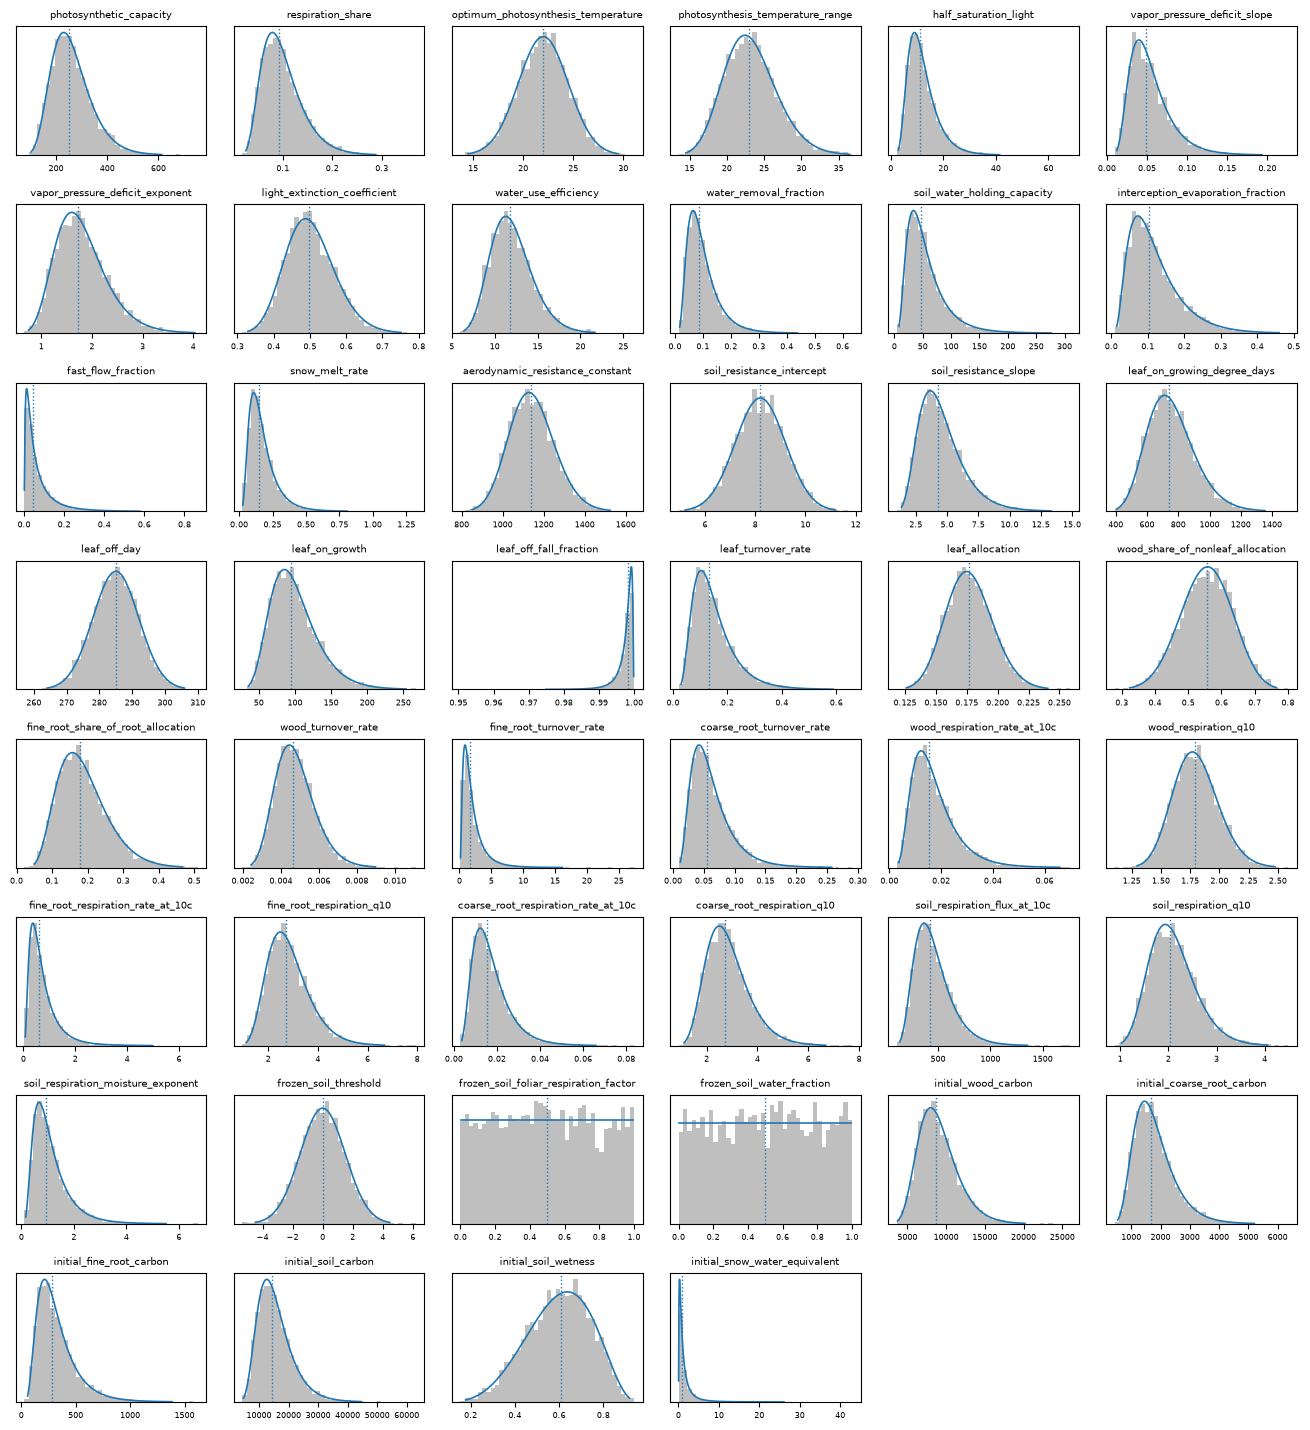

In [12]:
plots.plot_prior_marginals(problem, theta_draws);

## 4. SIPNET

SIPNET steps the forest's carbon and water pools forward every three hours. Its output
$x(\theta) \in \mathbb R^S$ is NEE at each of its $S = 37{,}992$ steps, from 2012 through 2024.
(The weather runs to 2024; the observations end in 2020.)

`problem.forward` hides the layers below. This section goes through them once, at the prior
medians: the calibration parameters become SIPNET parameters, and a `SIPNETSimulator` runs SIPNET
with the weather and the fixed values.

In [13]:
sipnet_parameters = calibration_to_sipnet(medians, data.fixed_sipnet_parameters)
simulator = SIPNETSimulator(data.driver_path, data.fixed_sipnet_parameters)
outputs = simulator.run(sipnet_parameters)
print(f"{len(sipnet_parameters)} SIPNET parameters; {len(outputs.data_vars)} outputs:")
print(", ".join(outputs.data_vars))

58 SIPNET parameters; 32 outputs:
wood_carbon, leaf_carbon, wood_growth, soil_carbon, coarse_root_carbon, fine_root_carbon, litter_carbon, soil_water, soil_wetness_fraction, snow_water_equivalent, net_primary_production, net_ecosystem_exchange, cumulative_net_ecosystem_exchange, gross_primary_production, above_ground_respiration, soil_respiration, root_respiration, autotrophic_respiration, heterotrophic_respiration, ecosystem_respiration, evapotranspiration, transpiration_rate, mineral_nitrogen, soil_organic_nitrogen, litter_nitrogen, plant_nitrogen_storage, nitrogen_volatilization, nitrogen_leaching, nitrogen_fixation, nitrogen_uptake, methane_production, wood_storage_carbon


`simulator.run` returns every output, with the same `attrs` as the weather. The forward map uses
only NEE, as a rate in µmol CO₂ m⁻² s⁻¹, the units of the data: a step's total NEE $N_s$
(g C m⁻²) over its length $\Delta_s$ (s) is the rate $x_s = 10^6 N_s / (12.011\, \Delta_s)$.
`simulator.nee_rate` returns $x(\theta)$:

In [14]:
x = simulator.nee_rate(sipnet_parameters)
x.shape

(37992,)

**Figure 3.** SIPNET at the prior medians, for one year. NEE is negative when the forest takes up
CO₂ (summer days) and positive when it releases it (nights, winter). Leaf carbon jumps when the
leaves come out in late spring and falls when they drop in autumn; soil water is drawn down in
summer. Both come back in section 6.

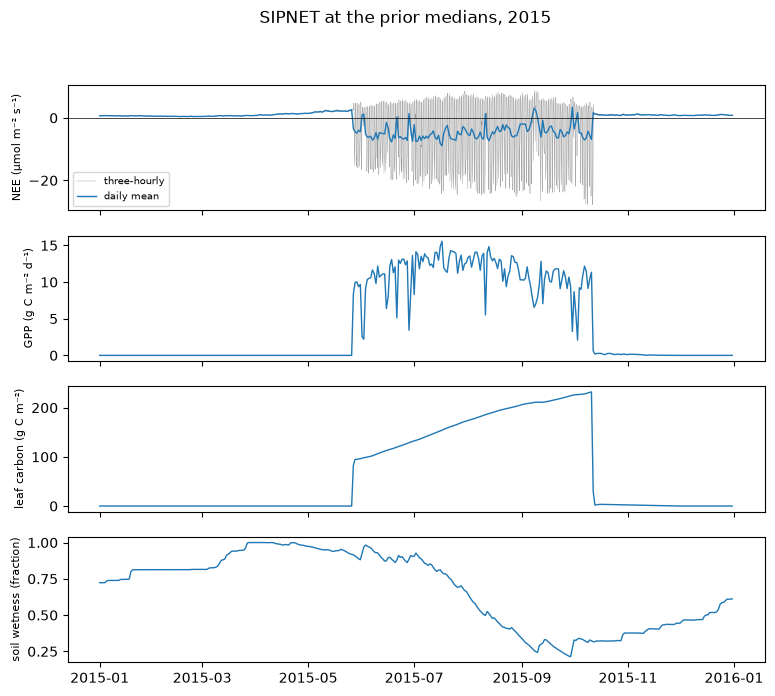

In [15]:
nee = pd.Series(x, index=data.step_ends)[str(YEAR)]
one_year = outputs.sel(time=str(YEAR))
figure, axes = plt.subplots(4, 1, figsize=(9, 7.5), sharex=True)
axes[0].plot(nee.index, nee, lw=0.3, color="0.6", label="three-hourly")
axes[0].plot(nee.resample("1D").mean(), lw=1, label="daily mean")
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set_ylabel("NEE (µmol m⁻² s⁻¹)", fontsize=8)
axes[0].legend(fontsize=7)
for axis, name, label in [
    (axes[1], "gross_primary_production", "GPP (g C m⁻² d⁻¹)"),
    (axes[2], "leaf_carbon", "leaf carbon (g C m⁻²)"),
    (axes[3], "soil_wetness_fraction", "soil wetness (fraction)"),
]:
    series = daily(one_year[name])
    axis.plot(series["time"], series, lw=1)
    axis.set_ylabel(label, fontsize=8)
figure.suptitle(f"SIPNET at the prior medians, {YEAR}");

## 5. The data and the observation operator

### The features

The tower measures NEE every half hour, with gaps. The data used here are averages over many
measurements, which are much less noisy than single ones. Each **feature** $y_i$ is the mean
observed NEE over the usable daytime (or night-time) three-hour windows $S_i$ of one half-month of
one year. There are 214 day features and 186 night features, 2012–2020. `data.features` is the
table, and `problem.data["nee"]` holds the values $y$:

In [16]:
data.features.head()

,class,year,month,half,n_steps,first_step_end_utc,last_step_end_utc,nee
0,day,2012,1,1,18,2012-01-03 18:00:00,2012-01-15 21:00:00,1.139514
1,day,2012,1,2,22,2012-01-16 21:00:00,2012-01-31 21:00:00,1.107639
2,day,2012,2,1,26,2012-02-01 21:00:00,2012-02-14 21:00:00,1.640604
3,day,2012,2,2,29,2012-02-17 15:00:00,2012-02-29 21:00:00,1.448754
4,day,2012,3,1,30,2012-03-01 18:00:00,2012-03-14 21:00:00,1.668431


In [17]:
y = problem.data["nee"]
data.features.groupby("class").agg(
    features=("nee", "size"), windows_per_feature=("n_steps", "median"), mean_nee=("nee", "mean")
)

,features,windows_per_feature,mean_nee
class,,,
day,214,25.0,-5.65303
night,186,11.0,2.96190


**Figure 4.** The 400 features, each at the middle of its half-month. Daytime NEE dips each summer
as the forest takes up carbon; night-time NEE, respiration alone, peaks each summer when it is
warm. `plots.plot_features` draws it; given predictions, it adds bands (section 8).

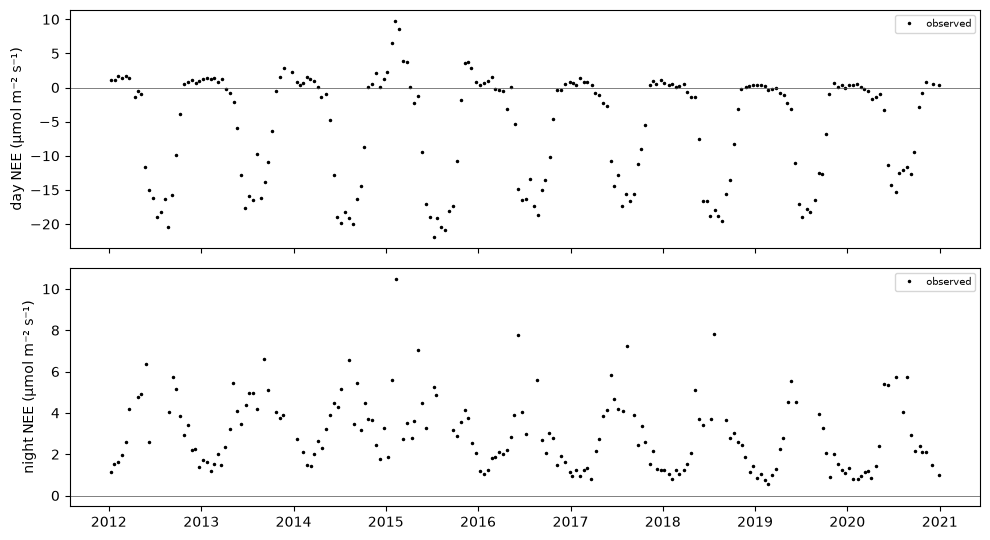

In [18]:
plots.plot_features(data);

### The observation operator

SIPNET's output must be averaged the same way as the data before the two can be compared. The
observation operator $A \in \mathbb R^{n \times S}$ does this:

$$
A_{is} = \begin{cases} 1/|S_i| & s \in S_i, \\ 0 & \text{otherwise,} \end{cases}
\qquad\text{so}\qquad (A\, x)_i = \frac{1}{|S_i|} \sum_{s \in S_i} x_s.
$$

Most entries are zero, so $A$ is stored as a sparse matrix:

In [19]:
A = data.operator
print(f"A is {A.shape[0]} × {A.shape[1]}, with {A.nnz} nonzero entries")

A is 400 × 37992, with 7588 nonzero entries


**Figure 5.** The operator on one half-month. The grey line is SIPNET's three-hourly NEE; the dots
mark the windows that the day and night features of 1–15 July average; the solid lines are the
averages $(A x)_i$ and the dashed lines the observed $y_i$. A day feature averages many more
windows than a night feature: summer nights are short, and many night windows are left out
because their measurements were gap-filled. This is one reason the two classes have different
noise levels (section 7).

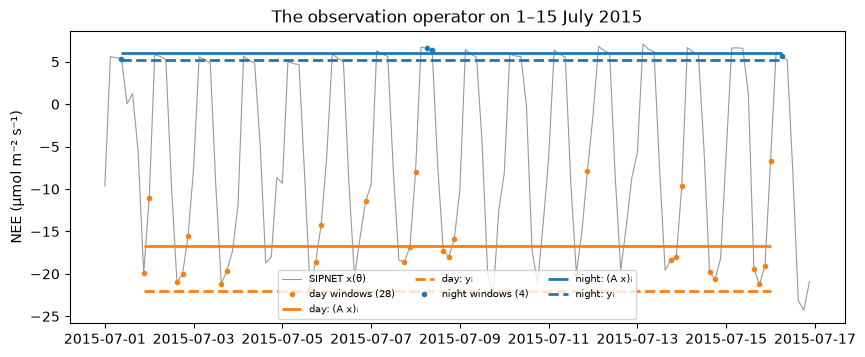

In [20]:
first_half_of_july = np.flatnonzero(
    (data.features["year"] == YEAR) & (data.features["month"] == 7) & (data.features["half"] == 1)
)
in_window = (data.step_ends >= f"{YEAR}-07-01") & (data.step_ends < f"{YEAR}-07-17")
predicted = A @ x
figure, axis = plt.subplots(figsize=(10, 3.8))
axis.plot(data.step_ends[in_window], x[in_window], color="0.6", lw=0.8, label="SIPNET x(θ)")
for row in first_half_of_july:
    feature_class = data.feature_classes[row]
    colour = "tab:orange" if feature_class == "day" else "tab:blue"
    steps = A[row].indices
    span = data.step_ends[steps[0]], data.step_ends[steps[-1]]
    axis.plot(
        data.step_ends[steps],
        x[steps],
        "o",
        ms=3,
        color=colour,
        label=f"{feature_class} windows ({len(steps)})",
    )
    axis.hlines(predicted[row], *span, color=colour, lw=2, label=f"{feature_class}: (A x)ᵢ")
    axis.hlines(y[row], *span, color=colour, lw=2, ls="--", label=f"{feature_class}: yᵢ")
axis.set(ylabel="NEE (µmol m⁻² s⁻¹)", title=f"The observation operator on 1–15 July {YEAR}")
axis.legend(fontsize=7, ncol=3);

## 6. The forward map

The **forward map** is $G(\theta) = A\, x(\theta)$: SIPNET's predicted features at the calibration
parameters $\theta$. `problem.forward` is a ProbPipe `Function`. Called on one parameter record, a
mapping from names to values, it runs SIPNET once and returns the 400 predicted features. ProbPipe
returns values wrapped with a record of where they came from; `.raw` is the plain array. At the
medians, it agrees with the $A\, x$ computed by hand above:

In [21]:
predicted_at_medians = np.asarray(problem.forward(medians).raw)
predicted_at_medians.shape, np.allclose(predicted_at_medians, A @ x)

((400,), True)

Called on a batch of records, such as the `theta` of 16 prior draws, it returns one row per record.
SIPNET runs in parallel, on up to 8 threads:

In [22]:
with workflow_run(seed=1):
    some_draws = sample(problem.prior, 16)

np.asarray(problem.forward(some_draws["theta"]).raw).shape

(16, 400)

The algorithms hold parameters as arrays rather than records. `problem.predicted_observations`
takes constrained parameters of shape $(N, 46)$, columns in the order of
`problem.coordinates.names`, and returns $G$ at each row, shape $(N, 400)$.

If SIPNET cannot run at a parameter setting, its row is NaN and a warning is logged, so that one
failure does not stop a batch. Here the second row sets the respiration share to 1.5, outside
its range $(0, 1)$. `calibration_to_sipnet` turns that into a negative maximum photosynthesis rate,
which pySIPNET refuses; the warning names every SIPNET parameter of the failed run and the reason:

In [23]:
names = problem.coordinates.names
theta_median = np.array([medians[name] for name in names])
impossible = theta_median.copy()
impossible[names.index("respiration_share")] = 1.5
predictions = problem.predicted_observations(np.stack([theta_median, impossible]))
np.isnan(predictions).all(axis=1)

SIPNET produced no output at {'daily_mean_photosynthesis_fraction': 0.860623, 'leaf_carbon_fraction': 0.466075, 'leaf_carbon_per_area': 30.7092, 'leaf_area_index': 0.0, 'leaf_on_day': 144.0, 'leaf_on_soil_temperature': 12.0, 'growth_respiration_fraction': 0.272493, 'litter_carbon': 0.0, 'litter_breakdown_rate': 0.4, 'litter_respired_fraction': 0.5, 'leaf_water_pool_depth': 0.200384, 'leaf_on_reallocation_fraction': 0.2, 'half_saturation_light': 10.999090871522062, 'vapor_pressure_deficit_slope': 0.04898979485566357, 'vapor_pressure_deficit_exponent': 1.7320508075688774, 'light_extinction_coefficient': 0.4969909455915671, 'water_use_efficiency': 11.757976016304852, 'water_removal_fraction': 0.08660254037844385, 'soil_water_holding_capacity': 47.434164902525694, 'interception_evaporation_fraction': 0.10324311242503326, 'fast_flow_fraction': 0.04434905427019852, 'snow_melt_rate': 0.15, 'aerodynamic_resistance_constant': 1138.3132257862937, 'soil_resistance_intercept': 8.2, 'soil_resistanc

array([False,  True])

**Figure 6.** One parameter at a time. Each column moves one parameter through its prior's 2.5%,
25%, 50%, 75% and 97.5% quantiles with the others at their medians, and shows the day and night
features of one year; the black dots are the data. These 20 settings are one call, so SIPNET runs
them in parallel.

- The photosynthetic capacity sets the depth of the summer daytime uptake, and, through leaf
  respiration, part of the night-time release.
- The soil's water-holding capacity matters in summer, when the soil dries: with a small capacity,
  the uptake collapses from July.
- The growing-degree days to leaf-on set when the uptake starts.
- The soil respiration flux at 10 °C sets the night-time release.

Each parameter is moved here with the others held fixed, so the figure cannot show how parameters
act together: two parameters can have the same effect on the features, so that the data inform
only a combination of them. Finding the combinations that the data inform is what the algorithms
in this repository do.

In [24]:
varied = [
    "photosynthetic_capacity",
    "soil_water_holding_capacity",
    "leaf_on_growing_degree_days",
    "soil_respiration_flux_at_10c",
]
levels = [0.025, 0.25, 0.5, 0.75, 0.975]
settings = []
for name in varied:
    law = marginal(problem.prior, f"theta/{name}")
    for level in levels:
        setting = theta_median.copy()
        setting[names.index(name)] = float(quantile(law, level))
        settings.append(setting)
one_at_a_time = problem.predicted_observations(np.array(settings))
one_at_a_time.shape

(20, 400)

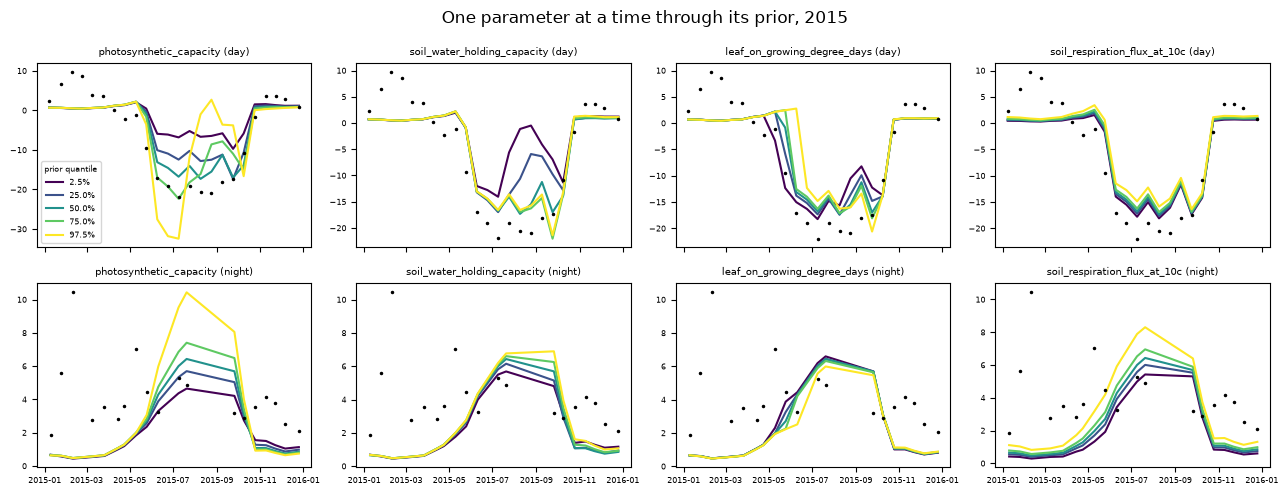

In [25]:
times = data.feature_times
colours = plt.cm.viridis(np.linspace(0, 1, len(levels)))
figure, axes = plt.subplots(2, len(varied), figsize=(13, 5), sharex=True)
for column, name in enumerate(varied):
    for row, feature_class in enumerate(["day", "night"]):
        in_year = np.flatnonzero((data.feature_classes == feature_class) & (times.year == YEAR))
        in_year = in_year[np.argsort(times[in_year])]
        axis = axes[row, column]
        for index, level in enumerate(levels):
            prediction = one_at_a_time[column * len(levels) + index]
            axis.plot(
                times[in_year], prediction[in_year], color=colours[index], label=f"{level:.1%}"
            )
        axis.plot(times[in_year], y[in_year], ".k", ms=3)
        axis.set_title(f"{name} ({feature_class})", fontsize=7)
        axis.tick_params(labelsize=6)
axes[0, 0].legend(fontsize=6, title="prior quantile", title_fontsize=6)
figure.suptitle(f"One parameter at a time through its prior, {YEAR}")
figure.tight_layout()

## 7. The likelihood

The likelihood says how far the data may fall from the predictions:

$$
y_i \mid \theta, s^2 \sim \mathcal N\!\left(G_i(\theta),\; s^2_{k(i)}\, v_i\right),
\qquad i = 1, \dots, n,
$$

independently across features. Three quantities set its width.

**The reference variances** $v_i = v_{k(i)}$ are one per class: $v_{\mathrm{day}} = 8$ and
$v_{\mathrm{night}} = 1.5$ (µmol m⁻² s⁻¹)². They cover both measurement error and the model's own
error, and are larger by day, when NEE and its errors are larger.

**The noise scales** $s^2_{\mathrm{day}}$ and $s^2_{\mathrm{night}}$ multiply them, and are
inferred with the data. Each has an inverse-gamma prior with shape 2 and scale 1.678 (that is,
$1/s^2_k$ has a gamma law with shape 2 and rate 1.678), whose median is 1. So a priori the
reference variances are right, but the data can widen or narrow each class's noise.

`problem.likelihood` holds $v$ and the classes $k(i)$, and `noise_variances` gives
$s^2_{k(i)}\, v_i$ for given scales:

In [26]:
likelihood = problem.likelihood
print("reference variances:", REFERENCE_VARIANCE)
print("noise-scale prior:", NOISE_SCALE_PRIOR)
print(
    "noise variances at s² = (2, 1):",
    np.unique(likelihood.noise_variances({"s2_day": 2.0, "s2_night": 1.0})),
)

reference variances: {'day': 8.0, 'night': 1.5}
noise-scale prior: {'concentration': 2.0, 'scale': 1.678}
noise variances at s² = (2, 1): [ 1.5 16. ]


`likelihood.pointwise_log_prob(given, y)` gives each feature's log-density
$\log \mathcal N(y_i \mid G_i(\theta), s^2_{k(i)} v_i)$, running SIPNET once at the given
parameters:

In [27]:
at_medians = {"theta": medians, "s2_day": 1.0, "s2_night": 1.0}
pointwise = np.asarray(likelihood.pointwise_log_prob(at_medians, y))
pointwise.shape, pointwise.sum()

((400,), np.float64(-997.4227706155393))

**The learning rate.** The errors of neighbouring half-months are correlated: a model error in
early July is likely to persist into late July. So the 400 features carry less information than
400 independent observations would, and the plain likelihood would give a posterior that is too
narrow. The likelihood is therefore *tempered*: each feature's log-likelihood is multiplied by a
learning rate $\eta_i \in (0, 1]$, chosen so that each class carries the information of $c = 3$
independent observations per year of data. For class $k$, with $n_k$ features spread over $M_k$
calendar months,

$$
\eta_k = \min\!\left(1,\; \frac{c\, M_k}{12\, n_k}\right).
$$

The table computes $\eta_k$ from the features and compares it with `problem.learning_rate`:

In [28]:
eta = problem.learning_rate["nee"]
calendar_month = data.features["year"] * 12 + data.features["month"]
by_class = data.features.assign(calendar_month=calendar_month).groupby("class")
learning_rates = by_class.agg(n_k=("nee", "size"), M_k=("calendar_month", "nunique"))
learning_rates["c M_k / (12 n_k)"] = (
    OBSERVATIONS_PER_CLASS_YEAR * learning_rates["M_k"] / (12 * learning_rates["n_k"])
)
learning_rates["problem.learning_rate"] = pd.Series(eta).groupby(data.feature_classes).first()
learning_rates

,n_k,M_k,c M_k / (12 n_k),problem.learning_rate
class,,,,
day,214,108,0.126168,0.126168
night,186,102,0.137097,0.137097


**The tempered noise covariance.** As a function of $\theta$, raising a Gaussian density to the
power $\eta_i$ is the same as dividing its variance by $\eta_i$:

$$
\mathcal N\!\left(y_i \mid G_i(\theta), s^2_{k(i)} v_i\right)^{\eta_i}
\;\propto\; \mathcal N\!\left(y_i \;\middle|\; G_i(\theta), \frac{s^2_{k(i)} v_i}{\eta_i}\right),
$$

where the constant depends on $s^2$ but not on $\theta$. So for fixed noise scales, the posterior
of $\theta$ is the prior times a Gaussian likelihood with covariance

$$
\Gamma = \operatorname{diag}\!\left(\frac{s^2_{k(i)}\, v_i}{\eta_i}\right).
$$

This is how the algorithms weight the data. (When the scales are inferred, the constant matters:
the posterior of $s^2$ must be computed from the tempered density, not from $\Gamma$.)
`problem.noise_variance(scales)` returns the diagonal of $\Gamma$. At $s^2 = 1$, the tempered noise standard
deviation $\sqrt{\Gamma_{ii}}$ is about 8 µmol m⁻² s⁻¹ by day and 3.3 by night:

In [29]:
gamma = problem.noise_variance({"s2_day": 1.0, "s2_night": 1.0})
pd.Series(np.sqrt(gamma)).groupby(data.feature_classes).first().rename("sqrt(Γ_ii)")

day      7.962877
night    3.307745
Name: sqrt(Γ_ii), dtype: float64

**Figure 7.** The residuals $y - G(\theta)$ at the prior medians, against two bands: $\pm 2
\sqrt{v_k}$, the plain likelihood's noise, and $\pm 2 \sqrt{\Gamma_{ii}}$, the tempered noise.
Most residuals fall inside the plain band, but they run in long stretches of one sign: the
correlation that the learning rate accounts for.

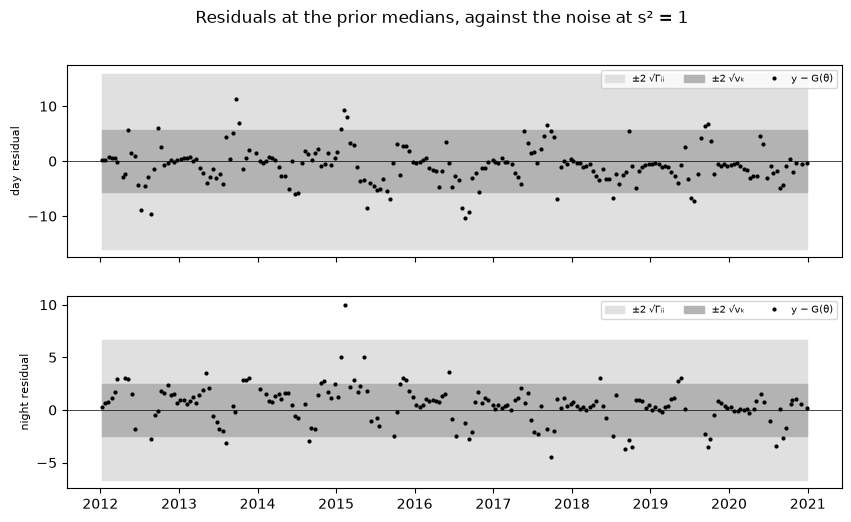

In [30]:
residual = y - predicted_at_medians
figure, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for axis, feature_class in zip(axes, ["day", "night"], strict=True):
    in_class = np.flatnonzero(data.feature_classes == feature_class)
    in_class = in_class[np.argsort(times[in_class])]
    tempered = np.sqrt(gamma[in_class])
    plain = np.sqrt(likelihood.reference_variance[in_class])
    axis.fill_between(times[in_class], -2 * tempered, 2 * tempered, color="0.88", label="±2 √Γᵢᵢ")
    axis.fill_between(times[in_class], -2 * plain, 2 * plain, color="0.7", label="±2 √vₖ")
    axis.plot(times[in_class], residual[in_class], ".", ms=4, color="k", label="y − G(θ)")
    axis.axhline(0, color="k", lw=0.5)
    axis.set_ylabel(f"{feature_class} residual", fontsize=8)
    axis.legend(fontsize=7, loc="upper right", ncol=3)
figure.suptitle("Residuals at the prior medians, against the noise at s² = 1");

**Figure 8.** The prior of each noise scale, $s^2_k \sim \mathrm{IG}(2, 1.678)$, with its median
of 1. Its long right tail lets the data raise a class's noise well above the reference variance.

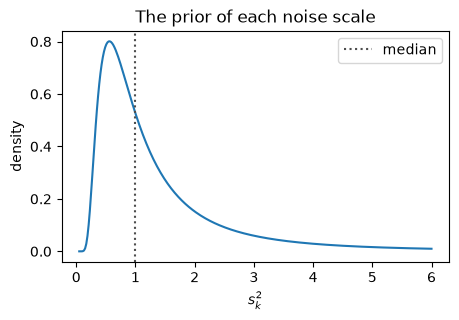

In [31]:
scale_law = marginal(problem.prior, "s2_day")
scale_grid = np.linspace(0.05, 6, 300)
scale_density = np.exp(
    np.asarray(log_prob(scale_law, NumericArrayBatch(scale_grid, level_names="grid", label="grid")))
)
figure, axis = plt.subplots(figsize=(5, 3))
axis.plot(scale_grid, scale_density)
axis.axvline(float(quantile(scale_law, 0.5)), ls=":", color="0.3", label="median")
axis.set(xlabel="$s^2_k$", ylabel="density", title="The prior of each noise scale")
axis.legend();

## 8. The prior predictive

Together, the likelihood and the prior are a **generative model** of the data: draw $\theta$ and
$s^2$ from the prior, run SIPNET, and add Gaussian noise. `problem.model` is this model, and
`sample(problem.model, n)` draws from it $n$ times, running SIPNET once per draw. The draws of the
data, the **prior predictive**, show what the model expects to see before it has seen the data.

The learning rate does not enter here: it weights the data in the posterior, but the model's noise
is the plain $s^2_{k(i)} v_i$.

In [32]:
with workflow_run(seed=2):
    replications = sample(problem.model, 200)

replicated_nee = np.asarray(replications["nee"].raw)
print(replicated_nee.shape, "with", np.isnan(replicated_nee).any(axis=1).sum(), "failed runs")

(200, 400) with 0 failed runs


A good prior predictive covers the data. The fraction of features inside the central 90% interval
of the replications, by class:

In [33]:
completed = replicated_nee[np.isfinite(replicated_nee).all(axis=1)]  # leave out failed runs
lower, upper = np.quantile(completed, [0.05, 0.95], axis=0)
inside = (y >= lower) & (y <= upper)
pd.Series(inside).groupby(data.feature_classes).mean().rename("inside the 90% interval")

day      0.953271
night    0.951613
Name: inside the 90% interval, dtype: float64

**Figure 9.** The median and the 50% and 90% bands of the replications, with the data. The prior
is wide, as it should be, and covers most of the data. Two things stand out: in most summers the
observed daytime uptake lies near the lower edge of the bands, and a few winter day features in
early 2015 lie above every replication.

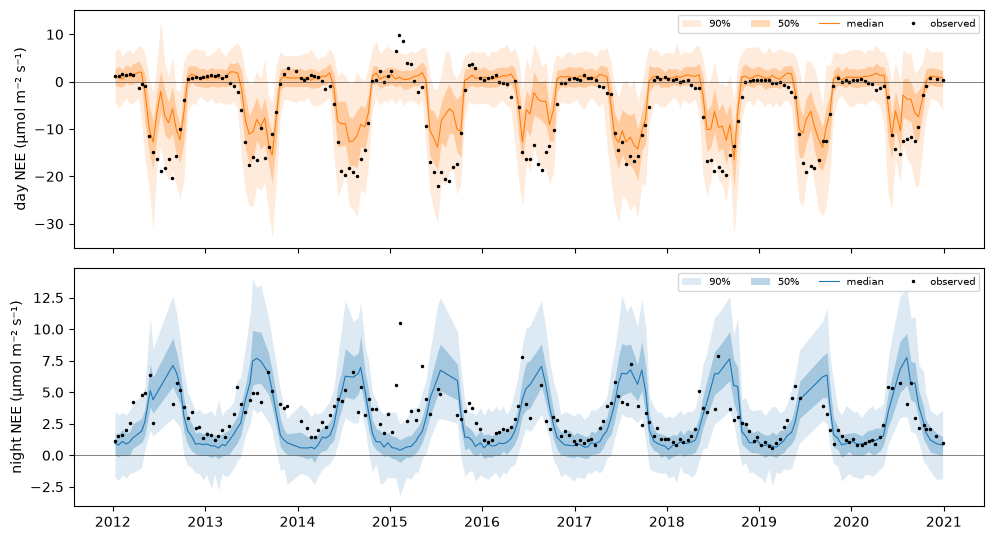

In [34]:
plots.plot_features(data, replicated_nee);

**Test statistics.** Coverage feature by feature can hide a systematic difference. A test
statistic $T$ summarizes a whole dataset; comparing $T(y)$ with $T$ of the replications checks one
aspect of the model. `predictive_check` draws the replications and computes each statistic on them
and on the data. Its p-value is the fraction of replications whose statistic is at least the
observed one, so a value near 0 or 1 means the data are unusual under the model.

Two statistics here: the mean of the summer (June–August) day features, which measures summer
uptake, and the mean of the night features, which measures respiration. A statistic receives one
replication of the data, an array of 400 features.

In [35]:
summer_day = np.flatnonzero(
    (data.feature_classes == "day") & data.features["month"].isin([6, 7, 8]).to_numpy()
)
night = np.flatnonzero(data.feature_classes == "night")


def mean_summer_day_nee(features):
    return features[summer_day].mean()


def mean_night_nee(features):
    return features[night].mean()


with workflow_run(seed=3):
    check = predictive_check(
        problem.likelihood,
        problem.prior,
        [mean_summer_day_nee, mean_night_nee],
        observed_data={"nee": y},
        num_replications=200,
    )

**Figure 10.** Each statistic's replicated values, with the observed value (black). The observed
mean summer daytime NEE is lower, that is more uptake, than most replications: the prior's
typical summer uptake is weaker than the forest's. The night-time mean is unremarkable. Neither
p-value is extreme, so the prior is consistent with the data, as a prior should be.

The replicated statistics come back as an `EmpiricalDistribution`, whose draws are `.atoms.raw`.

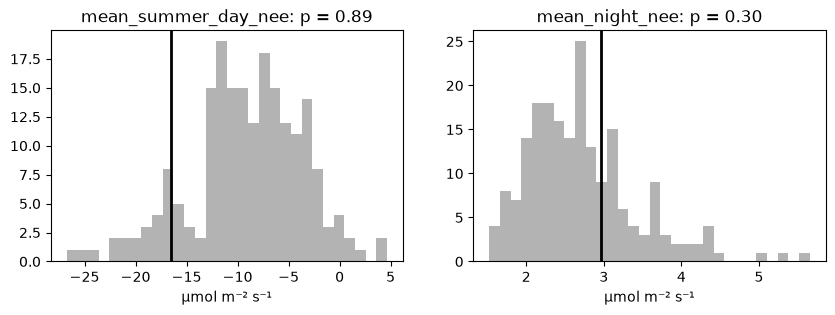

In [36]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3))
for axis, statistic in zip(axes, ["mean_summer_day_nee", "mean_night_nee"], strict=True):
    replicated = np.asarray(check[f"{statistic}/replicated_statistics"].atoms.raw)
    observed = float(check[f"{statistic}/observed_statistic"])
    p_value = float(check[f"{statistic}/p_value"])
    axis.hist(replicated, bins=30, color="0.7")
    axis.axvline(observed, color="k", lw=2)
    axis.set(xlabel="µmol m⁻² s⁻¹", title=f"{statistic}: p = {p_value:.2f}")

## 9. The posterior along one line

Computing the posterior is the subject of the next notebooks, but one line through parameter space
shows what the learning rate does. Hold every parameter but the photosynthetic capacity at its
median, and the noise scales at 1. Along that line, up to constants,

$$
\log \pi_\eta(\theta \mid y) = \log \pi_j(\theta_j)
+ \sum_{i=1}^{n} \eta_i \log \mathcal N\!\left(y_i \mid G_i(\theta), v_i\right),
$$

and the untempered posterior is the same with every $\eta_i = 1$. The grid is coarse across the
prior and fine near the posterior's peak, which is narrow.

In [37]:
name = "photosynthetic_capacity"
column = names.index(name)
law = marginal(problem.prior, f"theta/{name}")
variance = np.asarray(likelihood.noise_variances({"s2_day": 1.0, "s2_night": 1.0}))


def log_densities_along_line(values):
    """The log prior, untempered and tempered posterior at each value, up to constants."""
    theta = np.tile(theta_median, (len(values), 1))
    theta[:, column] = values
    predictions = problem.predicted_observations(theta)
    log_likelihood = -0.5 * ((y - predictions) ** 2 / variance + np.log(2 * np.pi * variance))
    on_grid = NumericArrayBatch(values, level_names="grid", label="grid")
    log_prior = np.asarray(log_prob(law, on_grid))
    return {
        "prior": log_prior,
        "posterior, η = 1": log_prior + log_likelihood.sum(axis=1),
        "posterior, tempered": log_prior + (eta * log_likelihood).sum(axis=1),
    }


coarse = np.linspace(float(quantile(law, 0.005)), float(quantile(law, 0.995)), 21)
peak = coarse[np.argmax(log_densities_along_line(coarse)["posterior, tempered"])]
spacing = coarse[1] - coarse[0]
values = np.union1d(coarse, np.linspace(peak - 1.5 * spacing, peak + 1.5 * spacing, 61))
curves = log_densities_along_line(values)

**Figure 11.** The three densities along the line, each normalized to integrate to 1 along it; the
right panel zooms in on the peak. Both posteriors are far narrower than the prior: the data inform
the photosynthetic capacity strongly. The tempered posterior is several times wider than the
untempered one, which is the learning rate at work. This is a slice with every other parameter
fixed, not the marginal posterior of the photosynthetic capacity, which is generally wider.

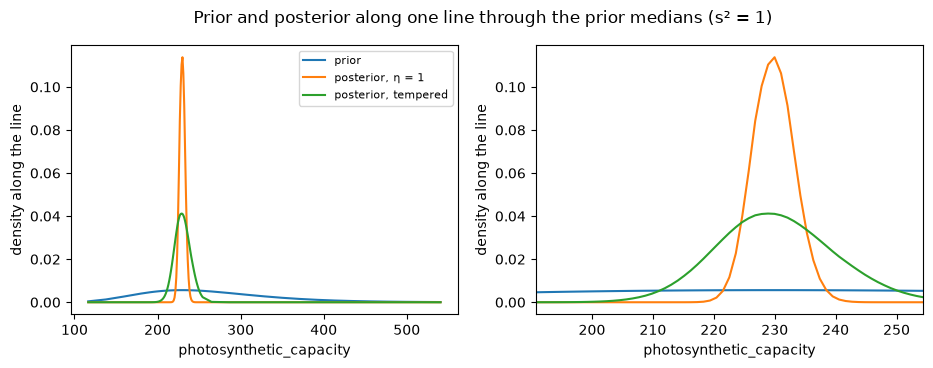

In [38]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for label, curve in curves.items():
    density = np.exp(curve - curve.max())
    density /= np.trapezoid(density, values)
    for axis in axes:
        axis.plot(values, density, label=label)
axes[1].set_xlim(peak - 1.5 * spacing, peak + 1.5 * spacing)
for axis in axes:
    axis.set(xlabel=name, ylabel="density along the line")
axes[0].legend(fontsize=8)
figure.suptitle("Prior and posterior along one line through the prior medians (s² = 1)");

## 10. Coordinates

The parameters have different units and ranges: the photosynthetic capacity is in the hundreds, a
respiration share is near 0.1, and many are bounded. The algorithms compare directions in
parameter space, so they need all the parameters on one scale. They use three coordinate systems:

- **constrained**, $\theta$: each parameter in its own units and range;
- **unconstrained**, $z = b^{-1}(\theta)$: each parameter mapped to the whole real line, by the
  logarithm for a positive parameter, the logit for one in $(0, 1)$, and the identity for one
  that is already unbounded;
- **whitened**, $\xi = L^{-1}(z - m)$, where $m$ and $L L^\top$ are the prior mean and covariance
  of $z$, so that $\xi$ has prior mean $0$ and covariance $I$.

`problem.coordinates` holds $b$, $m$ and $L$. Its maps act on arrays of shape $(\ldots, 46)$. The
whitened prior draws have mean 0 and covariance $I$, up to Monte Carlo error:

In [39]:
coordinates = problem.coordinates
z_draws = coordinates.bijection.to_unconstrained(theta_draws)
xi_draws = coordinates.whiten(z_draws)
covariance = np.cov(xi_draws, rowvar=False)
print("largest |mean|:", np.abs(xi_draws.mean(axis=0)).max().round(3))
identity = np.eye(coordinates.dimension)
print("largest |covariance − I|:", np.abs(covariance - identity).max().round(3))

largest |mean|: 0.043
largest |covariance − I|: 0.062


`coordinates.whitened_from_parameters` and `coordinates.parameters_from_whitened` go directly
between $\theta$ and $\xi$:

In [40]:
np.allclose(coordinates.parameters_from_whitened(xi_draws), theta_draws)

True

**Figure 12.** The prior draws of two parameters in each coordinate system: the photosynthetic
capacity (log-normal) and the respiration share (logit-normal). Each becomes normal in $z$, and
standard normal in $\xi$.

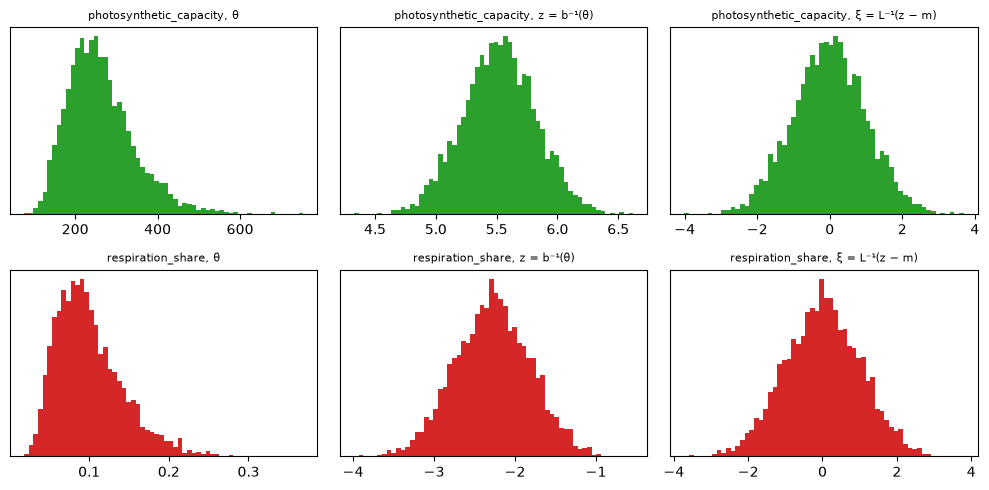

In [41]:
pair = ["photosynthetic_capacity", "respiration_share"]
systems = [(theta_draws, "θ"), (z_draws, "z = b⁻¹(θ)"), (xi_draws, "ξ = L⁻¹(z − m)")]
figure, axes = plt.subplots(len(pair), len(systems), figsize=(10, 5))
for row, name in enumerate(pair):
    for column, (draws, label) in enumerate(systems):
        axes[row, column].hist(draws[:, names.index(name)], bins=60, color=f"C{row + 2}")
        axes[row, column].set_title(f"{name}, {label}", fontsize=8)
        axes[row, column].set_yticks([])
figure.tight_layout()

## 11. Summary

| Symbol | Meaning | In code | Section |
|---|---|---|---|
| $\pi_\eta(\theta, s^2 \mid y)$ | the posterior | `problem.condition(method=...)` | next notebooks |
| $\theta$ | the 46 calibration parameters | `problem.coordinates.names` | 3 |
| $\pi(\theta)\, \pi(s^2)$ | the prior | `problem.prior`, `data.prior_table` | 3, 7 |
| $x(\theta)$ | SIPNET's NEE at each step | `SIPNETSimulator(...).nee_rate(...)` | 4 |
| $y$ | the observed features | `problem.data["nee"]`, `data.features` | 5 |
| $A$ | the observation operator | `data.operator` | 5 |
| $G(\theta)$ | the forward map | `problem.forward`, `problem.predicted_observations` | 6 |
| $v_k$, $s^2_k$ | reference variances and noise scales | `problem.likelihood` | 7 |
| $\eta$ | the learning rates | `problem.learning_rate["nee"]` | 7 |
| $\Gamma$ | the tempered noise covariance | `problem.noise_variance(...)` | 7 |
| $p(y \mid \theta, s^2)\, \pi(\theta, s^2)$ | the generative model | `problem.model` | 8 |
| $z$, $\xi$ | unconstrained and whitened coordinates | `problem.coordinates` | 10 |

The README's sections "The first algorithm" and "Comparing algorithms" show how to compute the
posterior and compare algorithms that do.